In [30]:
def add_geometries(rainfall_events_all_df):
    # Get shape file
    regions_shp = "/scratch/hydro5/users/la17355/FUTURE-FLOOD/Results/Pluvial/v4/#ss/plots/most_exposed_events_visualisation/by_region/ukcp18-uk-land-region-hires.shp"
    regions_df = gpd.read_file(regions_shp)

    # Create columns on regions_df and catchments_df (CATCHMENTS) with each of their geometries
    regions_df["region_geometry"] = regions_df.geometry
    CATCHMENTS["catchment_geometry"] = CATCHMENTS.geometry

    # Convert events dataframe to geodataframe
    rainfall_events_all_df = gpd.GeoDataFrame(rainfall_events_all_df,
                            geometry=gpd.points_from_xy(rainfall_events_all_df["x_coord"], rainfall_events_all_df["y_coord"]), 
                                              crs=regions_df.crs)

    # Remove old sjoin columns if this dataframe has been joined before
    rainfall_events_all_df = rainfall_events_all_df.drop(
        columns=["index_right", "geo_region", "region_geometry", "HA_NAME", "catchment_geometry"], errors="ignore")

    # Join events dataframe with the regions geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, regions_df[["geo_region", "region_geometry", "geometry"]],
        how="left", predicate="within")

    # Drop index_right before the next sjoin, or geopandas will error on the clash
    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")

    # Join events dataframe with the catchments geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, CATCHMENTS[["HA_NAME", "catchment_geometry", "geometry"]],
        how="left", predicate="within")

    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")
    return rainfall_events_all_df

def plot_polar_months_plot(df, ax, title_on, title, rmax, name_variable_to_plot, original_D_mean, R):
    D_mean = 365 - round(original_D_mean, 0)
    N = 12
    width = (2 * np.pi) / N

    circular_bins = np.linspace(0.0, 2 * np.pi, N, endpoint=False)
    circular_bins = np.append(circular_bins, 2 * np.pi)
    circular_plot_position = circular_bins + 0.5 * np.diff(circular_bins)[0]
    circular_plot_position = circular_plot_position[:-1]
    circular_plot_position = circular_plot_position + 0.5 * np.pi

    count = df['month'].value_counts().sort_index()
    count = count.reindex(list(range(1, 13)), fill_value=0)

    total_events = count.sum()
    percentage = (count / total_events) * 100 if total_events > 0 else count

    if name_variable_to_plot == 'Percentage':
        variable_to_plot = percentage
    elif name_variable_to_plot == 'Count':
        variable_to_plot = count

    colors = ['#C2DFFF', '#C2DFFF', '#A8E6CF', '#A8E6CF', '#A8E6CF', '#FFD3B6', '#FFD3B6', '#FFD3B6',
              '#FFABAB', '#FFABAB', '#FFABAB', '#C2DFFF']
    colors.reverse()

    ax.bar(circular_plot_position, variable_to_plot.iloc[::-1], width=width, color=colors)

    mean_angle = (D_mean / 365) * 2 * np.pi + 0.5 * np.pi
    line_length = R * rmax

    ax.annotate('', xy=(mean_angle, line_length), xytext=(mean_angle, 0),
                arrowprops=dict(facecolor='black', edgecolor='black', arrowstyle='-|>', linewidth=4))

    ax.text(0.8, 0.35, f'D: {int(original_D_mean)} \nR: {round(R, 2)}',
            ha='center', va='center', transform=ax.transAxes, fontsize=12, fontweight='bold')

    if title_on:
        ax.set_title(title, fontsize=16, pad=40, fontweight='bold')
    ax.set_rlabel_position(90)
    ax.xaxis.grid(False)

    if name_variable_to_plot == 'Percentage':
        ax.set_ylim(0, rmax)

    ax.set_xticks(circular_plot_position - 0.5 * np.pi)
    ax.set_xticklabels(['Mar', 'Feb', 'Jan', 'Dec', 'Nov', 'Oct', 'Sep', 'Aug', 'Jul', 'Jun', 'May', 'Apr'])
    
def circular_mean_day_and_R(day_of_year_series, n_days=360):
    angles = (day_of_year_series / n_days) * 2 * np.pi
    mean_sin = np.sin(angles).mean()
    mean_cos = np.cos(angles).mean()
    R = np.sqrt(mean_sin**2 + mean_cos**2)
    mean_angle = np.arctan2(mean_sin, mean_cos) % (2 * np.pi)
    D_mean = (mean_angle / (2 * np.pi)) * n_days
    return D_mean, R    

    
def plot_polar_months_overlay(df_present, df_future, ax, title_on=False, title=None, legend_on=False, vmax=None):
    N = 12
    width = (2 * np.pi) / N

    circular_bins = np.linspace(0.0, 2 * np.pi, N, endpoint=False)
    circular_bins = np.append(circular_bins, 2 * np.pi)
    circular_plot_position = circular_bins + 0.5 * np.diff(circular_bins)[0]
    circular_plot_position = circular_plot_position[:-1]
    circular_plot_position = circular_plot_position + 0.5 * np.pi

    count_present = df_present['month'].value_counts().reindex(range(1, 13), fill_value=0)
    count_future = df_future['month'].value_counts().reindex(range(1, 13), fill_value=0)

    percentage_present = (count_present / count_present.sum() * 100) if count_present.sum() > 0 else count_present
    percentage_future = (count_future / count_future.sum() * 100) if count_future.sum() > 0 else count_future

    overlap_percentage = np.minimum(percentage_present, percentage_future)
    present_only_percentage = percentage_present - overlap_percentage
    future_only_percentage = percentage_future - overlap_percentage

    colors_present = 'royalblue'
    colors_future = 'indianred'

    if vmax is None:
        vmax = max(percentage_present.max(), percentage_future.max()) * 1.1

    # Full bars first (so the taller of the two shows its "only" colour where it extends beyond the other)
    ax.bar(circular_plot_position, percentage_present.iloc[::-1], width=width, color=colors_present, alpha=1, label='Present')
    ax.bar(circular_plot_position, percentage_future.iloc[::-1], width=width, color=colors_future, alpha=1, label='Future')
    # Overlap drawn on top, in grey, up to whichever is smaller at each month
    ax.bar(circular_plot_position, overlap_percentage.iloc[::-1], width=width, color='lightgrey', alpha=1, label='Overlap')

    if title_on:
        ax.set_title(title, fontsize=16, pad=40, fontweight='bold')
    if legend_on:
        ax.legend(loc='upper right', fontsize=9)

    ax.set_rlabel_position(90)
    ax.xaxis.grid(False)
    ax.set_ylim(0, vmax)
    ax.set_xticks(circular_plot_position - 0.5 * np.pi)
    ax.set_xticklabels(['Mar','Feb','Jan','Dec','Nov','Oct','Sep','Aug','Jul','Jun','May','Apr'])

In [31]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
import geopandas as gpd
import sys

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENTS

## ------------------------------------------------------------ ###
### Get rainfall events
    And add extra variables
## ------------------------------------------------------------ ###

In [32]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['start_year']>1991].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")

rainfall_events_all_df['fu_at_peak_old_mm'] = rainfall_events_all_df['fu_at_peak_old']*1000
rainfall_events_all_df['HC_status'] = pd.cut(rainfall_events_all_df['hc_at_peak'],
    bins=[-float('inf'), 0.15, 1.1, 3, float('inf')],labels=['D', 'C', 'B', 'A'], right=False, include_lowest=True)

## ------------------------------------------------------------ ###
### Get spatial data and add regional geometries to rainfall data
## ------------------------------------------------------------ ###

In [33]:
rainfall_events_all_df  = add_geometries(rainfall_events_all_df)

## ------------------------------------------------------------ ###
### Add column defining which of 3 temporal periods an event is within
## ------------------------------------------------------------ ###

In [34]:
conditions = [rainfall_events_all_df["start_year"].between(1990, 2020),rainfall_events_all_df["start_year"].between(2020, 2060),
    rainfall_events_all_df["start_year"].between(2060, 2080),]
periods = ["1990–2020", "2020–2050", "2060–2080"]

rainfall_events_all_df["period"] = np.select(conditions, periods, default=None)

## ------------------------------------------------------------ ###
### Add column defining intensity bins
## ------------------------------------------------------------ ###

In [35]:
bins = [30, 35, 40, 45, 50, 60, 70, np.inf]
bins = [30,  40,  50, 60, 70, np.inf]
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-2)] + ["100+"]
rainfall_events_all_df["intensity_bin"] = pd.cut(rainfall_events_all_df["max_precip"], bins=bins, labels=labels, include_lowest=True)

## ------------------------------------------------------------ ###
### Add column defining seasons
## ------------------------------------------------------------ ###

In [36]:
season_map = {12:'DJF',1:'DJF',2:'DJF', 3:'MAM',4:'MAM',5:'MAM',
              6:'JJA',7:'JJA',8:'JJA', 9:'SON',10:'SON',11:'SON'}
rainfall_events_all_df['season'] = rainfall_events_all_df['month'].map(season_map)

In [37]:
# dfs_by_period = {
#     label: rainfall_events_all_df[
#         (rainfall_events_all_df['intensity_bin'] == target_bin) &
#         (rainfall_events_all_df['period'] == label)
#     ]
#     for label in periods
# }

# fig, ax = plt.subplots(figsize=(7,7), subplot_kw={'polar': True})
# plot_polar_months_multi(dfs_by_period, ax, title_on=True, title=f'Seasonal mix — {target_bin} mm/hr events', vmax=25)
# plt.show()    

In [38]:
colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))
color_map = dict(zip(periods, colors))

In [39]:
rainfall_events_all_df["duration_bin"] = pd.cut(
    rainfall_events_all_df["length_of_active_rain"],
    bins=[0, 6, 16, np.inf],
    labels=["≤7hr", "7–16hr", "16hr+"])

duration_bins = ["≤7hr", "7–16hr", "16hr+"]
period_rows = [periods[0], periods[2]]  # adjust to your actual labels/order

# Shared rmax across every panel, so radial scale is comparable
rmax = 0
for period_label in period_rows:
    for dbin in duration_bins:
        sub = rainfall_events_all_df[
            (rainfall_events_all_df["period"] == period_label) &
            (rainfall_events_all_df["duration_bin"] == dbin)
        ]
        counts = sub['month'].value_counts().reindex(range(1, 13), fill_value=0)
        pct = (counts / counts.sum() * 100) if counts.sum() > 0 else counts
        rmax = max(rmax, pct.max())
rmax *= 1.15

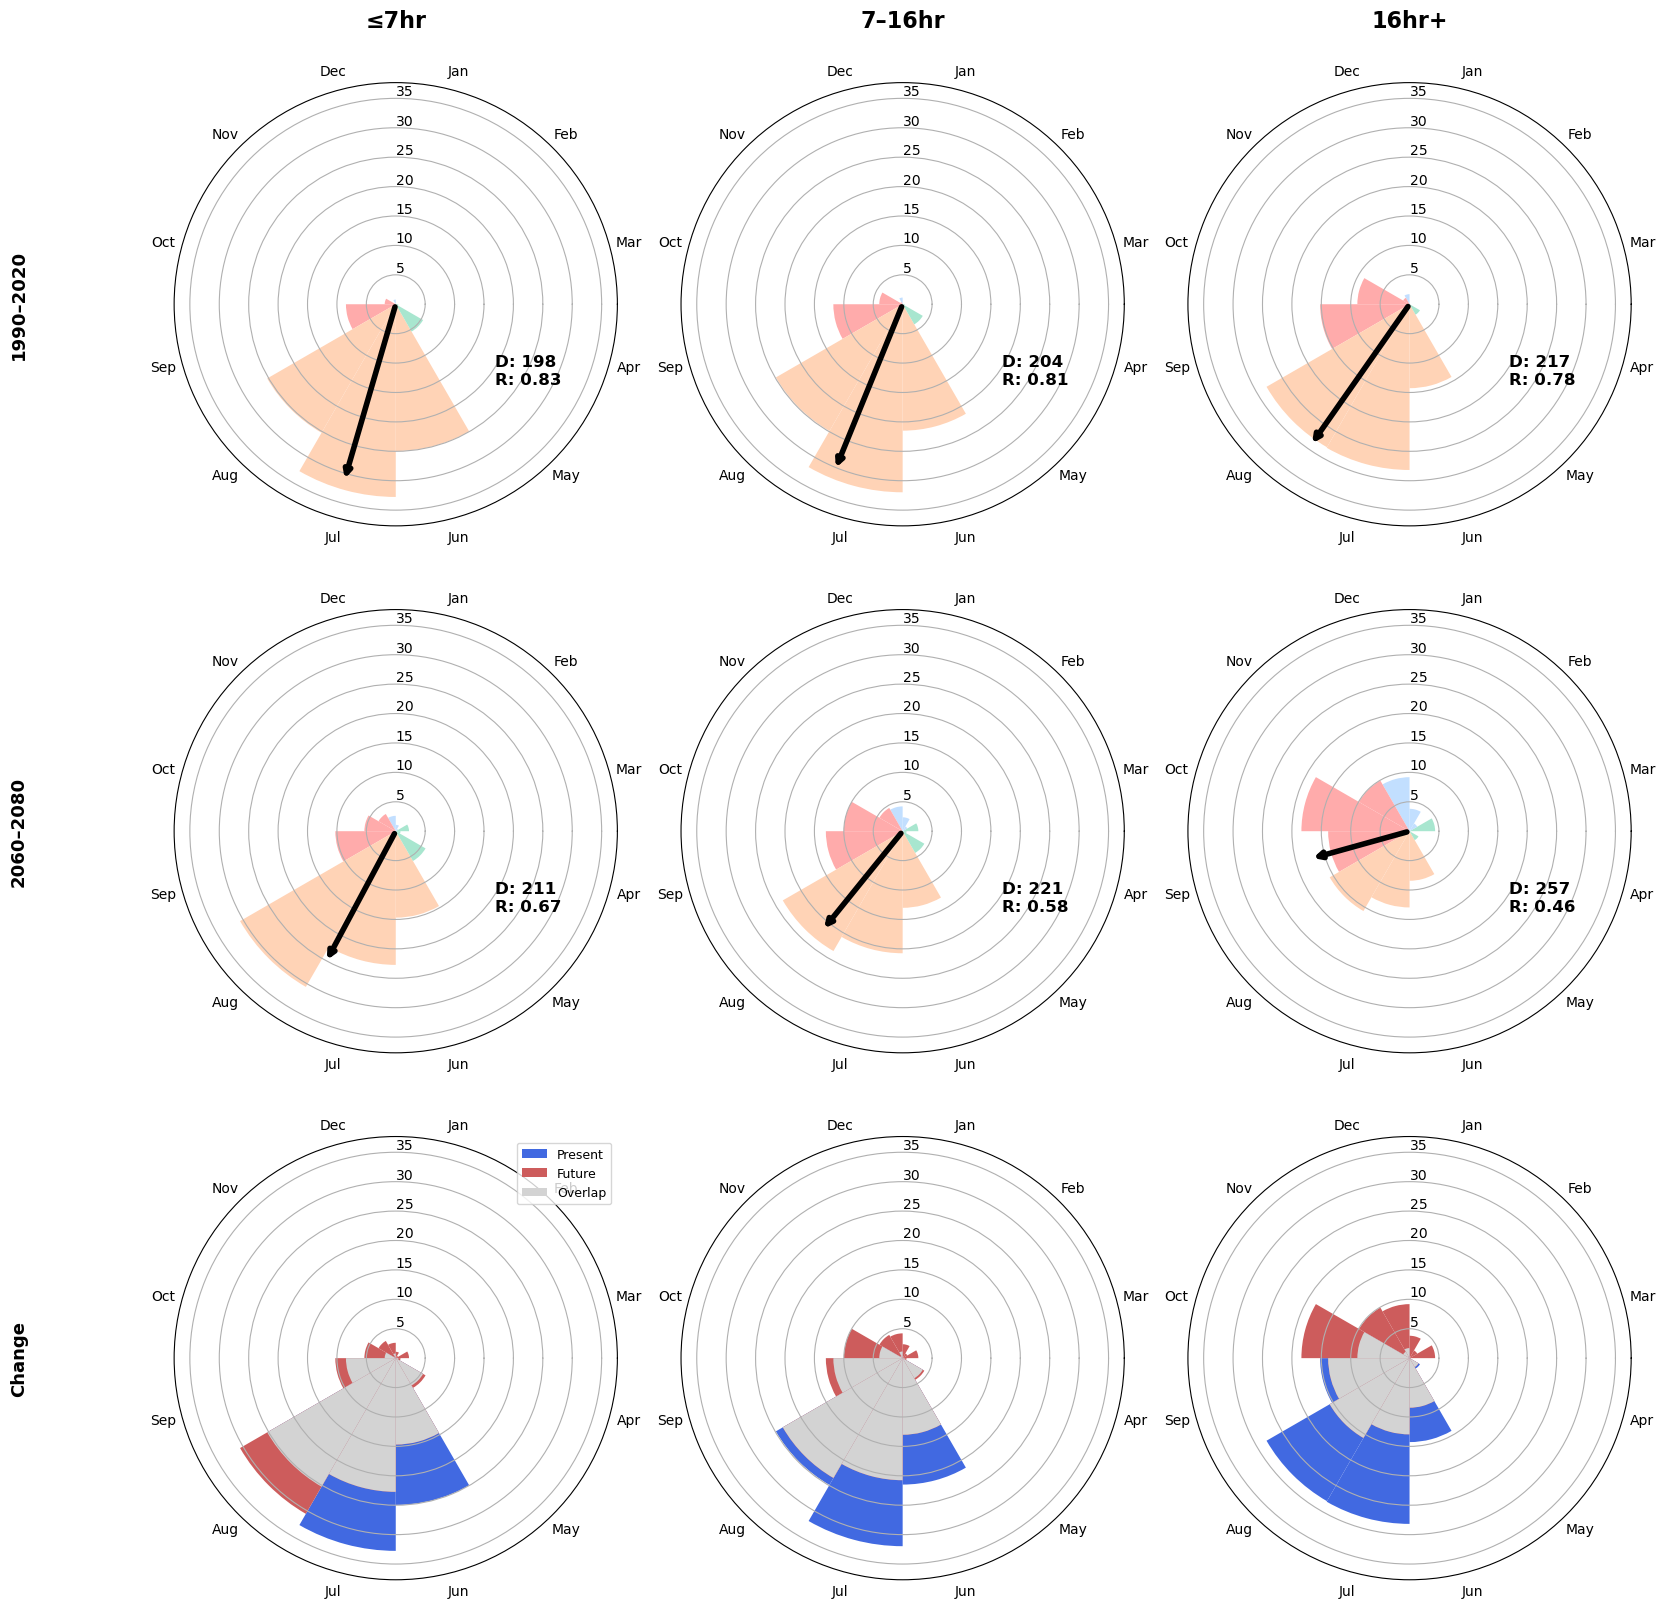

In [40]:
fig, axes = plt.subplots(3, len(duration_bins),
                          figsize=(5.5*len(duration_bins), 16.5),
                          subplot_kw={'polar': True})

row_labels = [periods[0], periods[2], 'Change']

for col, dbin in enumerate(duration_bins):
    sub_present = rainfall_events_all_df[
        (rainfall_events_all_df["period"] == periods[0]) &
        (rainfall_events_all_df["duration_bin"] == dbin)]
    sub_future = rainfall_events_all_df[
        (rainfall_events_all_df["period"] == periods[2]) &
        (rainfall_events_all_df["duration_bin"] == dbin)]

    D_mean_p, R_p = circular_mean_day_and_R(sub_present['day_360'])
    D_mean_f, R_f = circular_mean_day_and_R(sub_future['day_360'])

    plot_polar_months_plot(sub_present, axes[0, col], title_on=(col == 0 or True), title=dbin,
                            rmax=rmax, name_variable_to_plot='Percentage',
                            original_D_mean=D_mean_p, R=R_p)

    plot_polar_months_plot(sub_future, axes[1, col], title_on=False, title=dbin,
                            rmax=rmax, name_variable_to_plot='Percentage',
                            original_D_mean=D_mean_f, R=R_f)

    plot_polar_months_overlay(sub_present, sub_future, axes[2, col],
                               legend_on=(col == 0), vmax=rmax)

for row in range(3):
    axes[row, 0].text(-0.35, 0.5, row_labels[row], transform=axes[row, 0].transAxes,
                        fontsize=13, fontweight='bold', rotation=90, va='center', ha='center')

plt.tight_layout()
plt.show()

In [41]:
for col, dbin in enumerate(duration_bins):
    sub_present = rainfall_events_all_df[
        (rainfall_events_all_df["period"] == periods[0]) &
        (rainfall_events_all_df["duration_bin"] == dbin)]
    sub_future = rainfall_events_all_df[
        (rainfall_events_all_df["period"] == periods[2]) &
        (rainfall_events_all_df["duration_bin"] == dbin)]

    D_mean_p, R_p = circular_mean_day_and_R(sub_present['day_360'])
    D_mean_f, R_f = circular_mean_day_and_R(sub_future['day_360'])

    plot_polar_months_plot(sub_present, axes[0, col], title_on=(col == 0 or True), title=dbin,
                            rmax=rmax, name_variable_to_plot='Percentage',
                            original_D_mean=D_mean_p, R=R_p)

    plot_polar_months_plot(sub_future, axes[1, col], title_on=False, title=dbin,
                            rmax=rmax, name_variable_to_plot='Percentage',
                            original_D_mean=D_mean_f, R=R_f)

    plot_polar_months_overlay(sub_present, sub_future, axes[2, col],
                               legend_on=(col == 0), vmax=rmax)


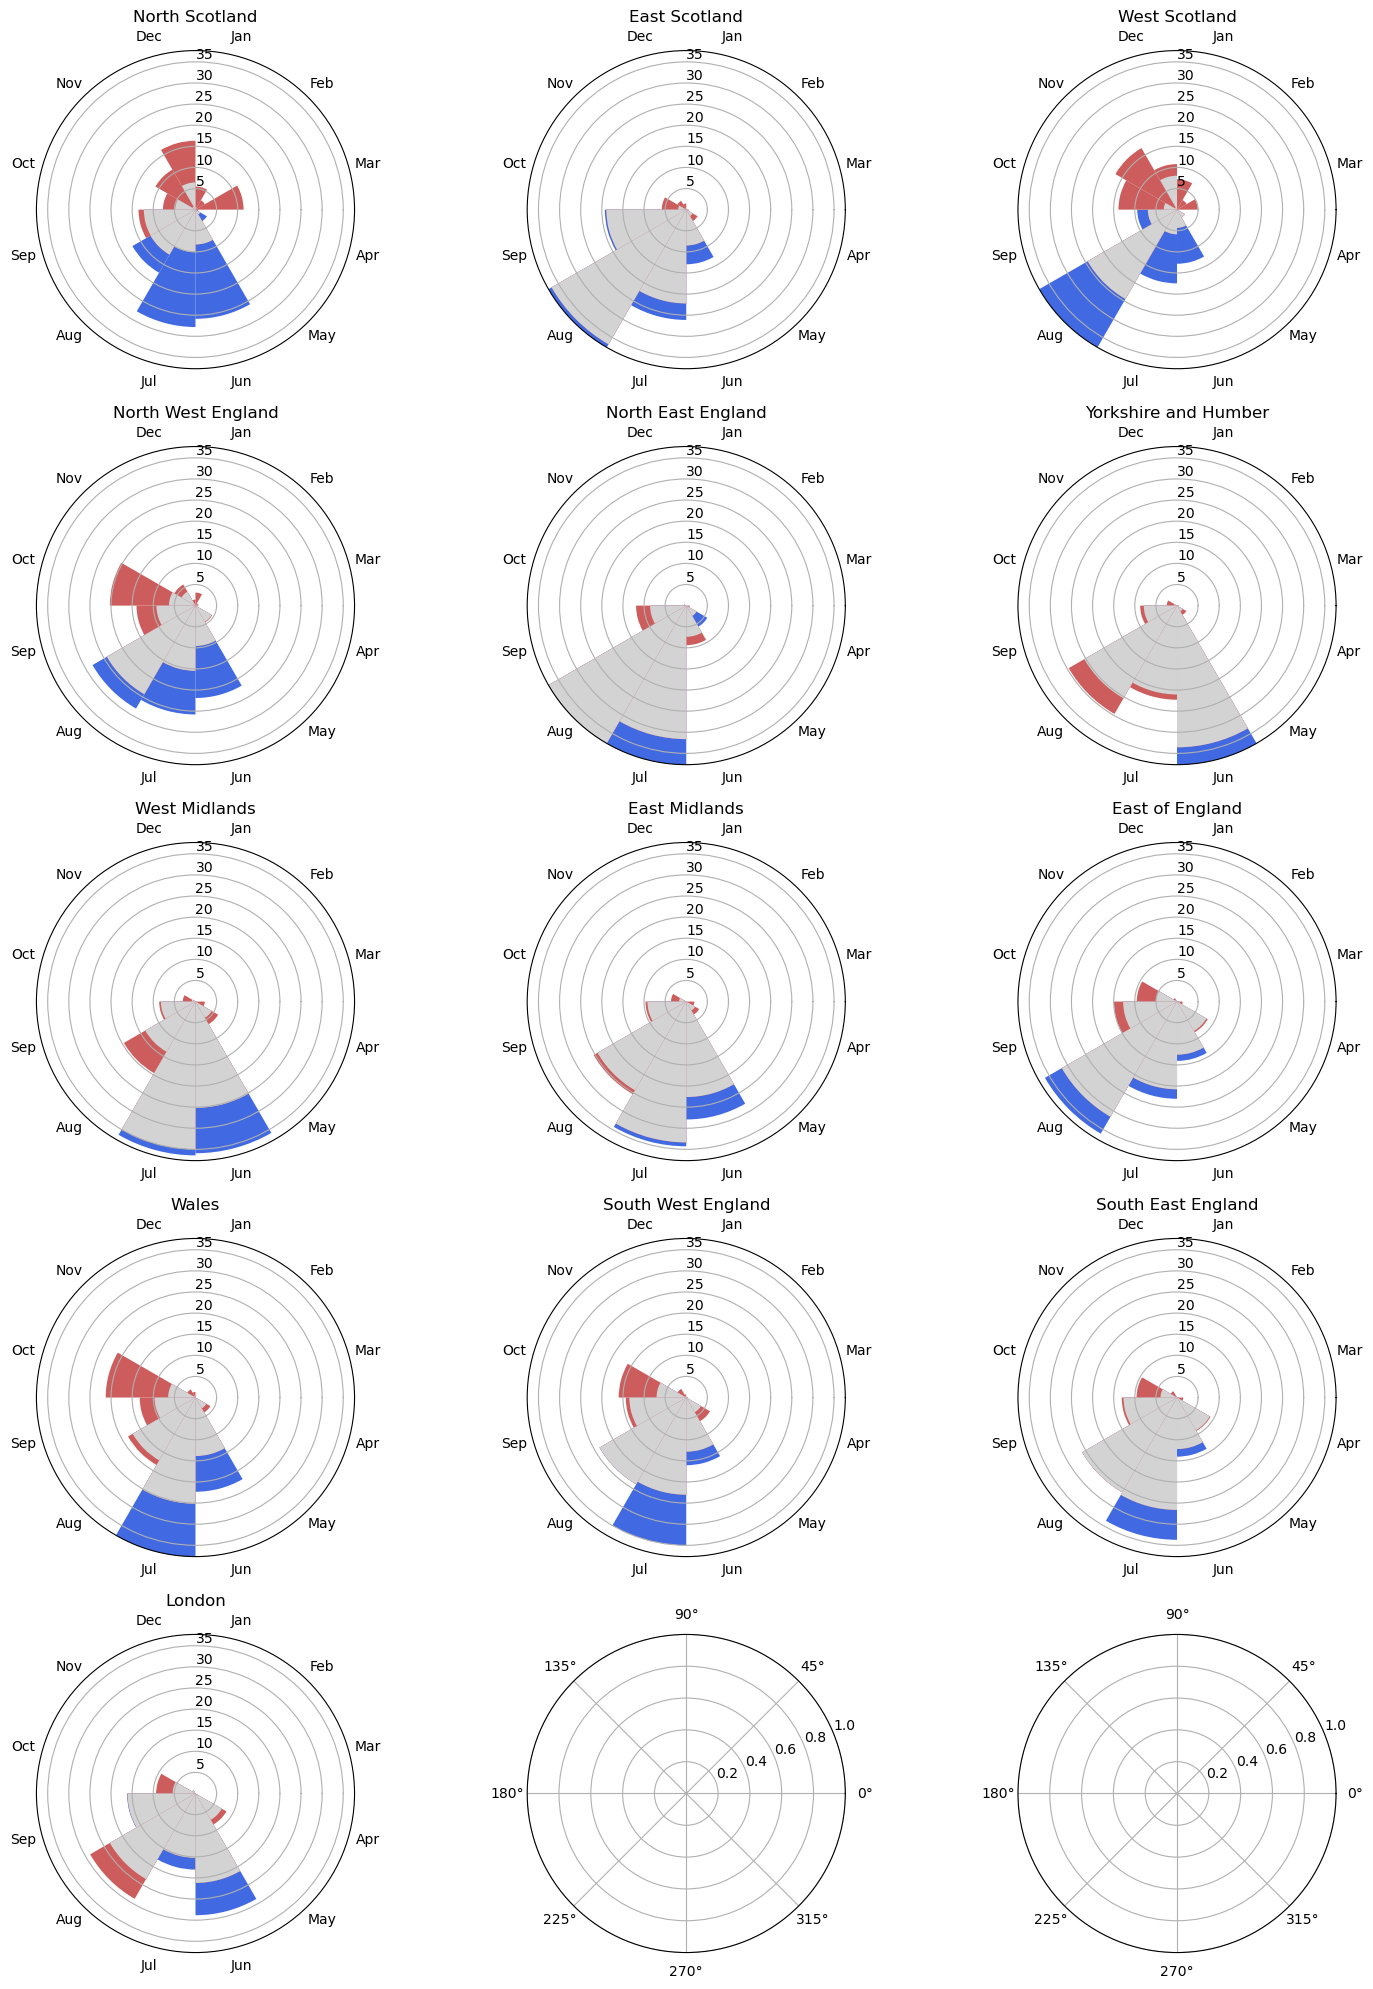

In [42]:
fig, axes = plt.subplots(5, 3, figsize=(15, 20), subplot_kw={'polar': True})
axes = axes.flatten()

for i, region in enumerate(region_order):
    this_region = rainfall_events_all_df[rainfall_events_all_df['geo_region']==region]
    sub_present = this_region[(this_region["period"] == periods[0])]
    sub_future = this_region[(this_region["period"] == periods[2])]
    plot_polar_months_overlay(sub_present, sub_future, axes[i],
                               legend_on=(col == 0), vmax=rmax)
    axes[i].set_title(region)

plt.tight_layout()
plt.show()

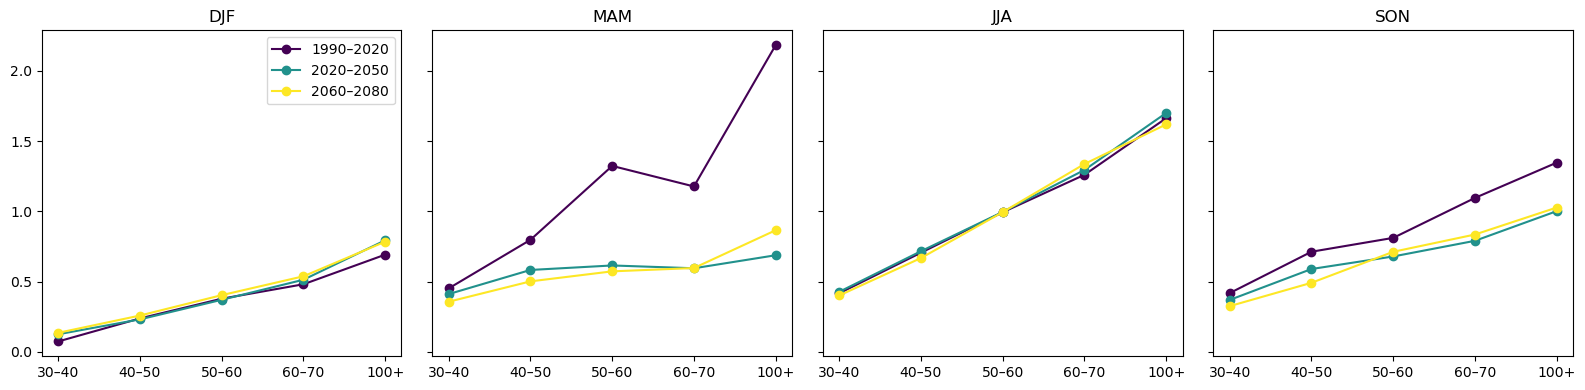

In [43]:
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = rainfall_events_all_df[rainfall_events_all_df['season'] == season]
    summary = sub.groupby(["period", "intensity_bin"], observed=True)["10cm_area"].mean().unstack()
    for choice in periods:
        if choice in summary.index:
            ax.plot(summary.columns, summary.loc[choice], marker="o", color=color_map[choice], label=choice)
    ax.set_title(season)
axes[0].legend()
plt.tight_layout()
plt.show()

In [15]:
region_order = ["North Scotland","East Scotland","West Scotland","North West England","North East England",
                "Yorkshire and Humber","West Midlands","East Midlands","East of England","Wales",
                "South West England","South East England","London"]

In [16]:
from scipy import stats

trend_results = []
period_numeric = {'1990–2020': 0, '2020–2050': 1, '2050–2080': 2}  # adjust to your actual labels

for region in region_order:
    # Get data just this region
    sub = rainfall_events_all_df[rainfall_events_all_df['geo_region'] == region]
    # For each intensity bin
    for ibin in sub['intensity_bin'].cat.categories:
        bsub = sub[sub['intensity_bin'] == ibin].copy()
        bsub['period_num'] = bsub['period'].map(period_numeric)
        if bsub['period_num'].nunique() < 2:
            continue
        slope, intercept, r, p, se = stats.linregress(bsub['period_num'], bsub['10cm_volume'])
        trend_results.append({'region': region, 'intensity_bin': ibin, 'slope': slope, 'p_value': p, "se": se})

trend_df = pd.DataFrame(trend_results)
# trend_df[trend_df['p_value'] < 0.05]  # which region/bin combinations show a credible trend

In [17]:
# sub = trend_df[trend_df['intensity_bin'] == target_bin].sort_values('slope').reset_index(drop=True)
target_bin = '30–40'

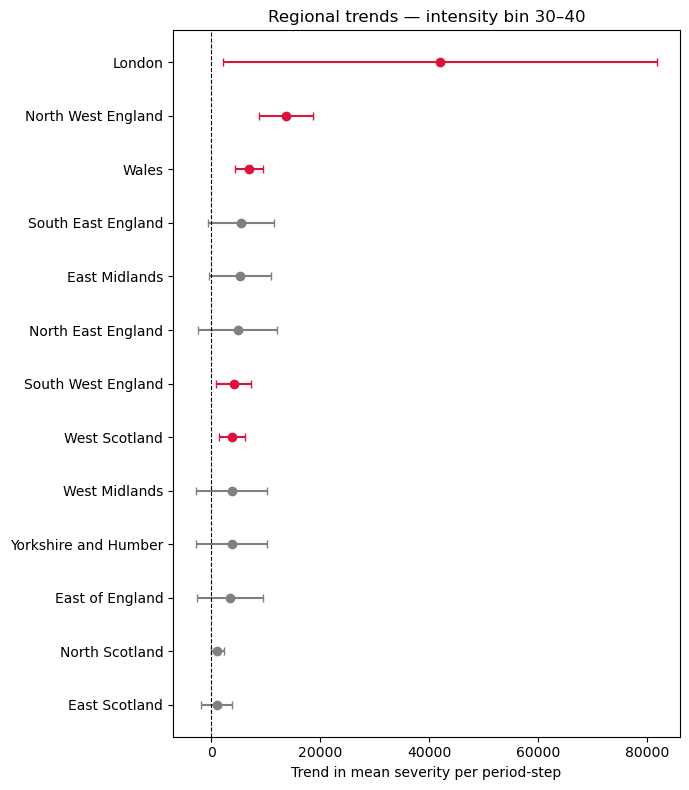

In [18]:
fig, ax = plt.subplots(figsize=(7, 8))

sub = trend_df[trend_df['intensity_bin'] == target_bin].sort_values('slope').reset_index(drop=True)
y_pos = np.arange(len(sub))

for i, row in sub.iterrows():
    color = 'crimson' if row['p_value'] < 0.05 else 'grey'
    ax.errorbar(row['slope'], y_pos[i], xerr=1.96*row['se'], fmt='o', capsize=3, color=color)

ax.axvline(0, color='k', lw=0.8, linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels(sub['region'])
ax.set_xlabel('Trend in mean severity per period-step')
ax.set_title(f'Regional trends — intensity bin {target_bin}')
plt.tight_layout()
plt.show()

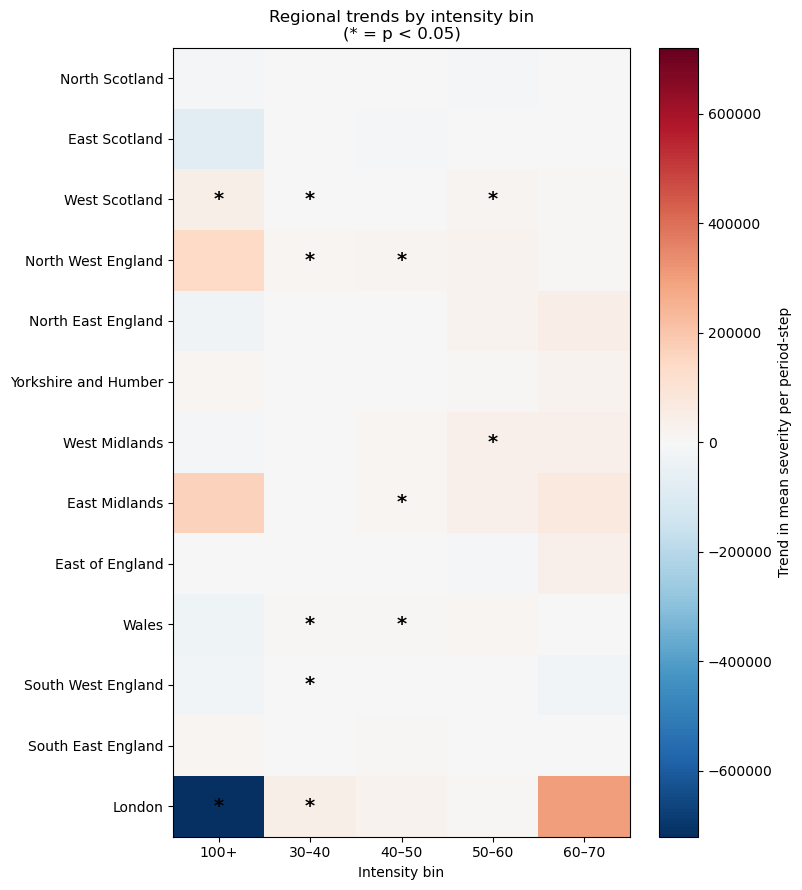

In [19]:
# Pivot trend_df into a region x intensity_bin grid of slopes
slope_grid = trend_df.pivot(index='region', columns='intensity_bin', values='slope')
pval_grid = trend_df.pivot(index='region', columns='intensity_bin', values='p_value')

# Order rows consistently (e.g. by overall mean slope, or your existing region_order)
slope_grid = slope_grid.reindex(region_order)
pval_grid = pval_grid.reindex(region_order)

fig, ax = plt.subplots(figsize=(8, 9))

vmax = np.nanmax(np.abs(slope_grid.values))
im = ax.imshow(slope_grid.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')

# Mark significant cells with an asterisk
for i in range(slope_grid.shape[0]):
    for j in range(slope_grid.shape[1]):
        p = pval_grid.values[i, j]
        if not np.isnan(p) and p < 0.05:
            ax.text(j, i, '*', ha='center', va='center', color='black', fontsize=14, fontweight='bold')

ax.set_xticks(range(len(slope_grid.columns)))
ax.set_xticklabels(slope_grid.columns)
ax.set_yticks(range(len(slope_grid.index)))
ax.set_yticklabels(slope_grid.index)
ax.set_xlabel('Intensity bin')
plt.colorbar(im, ax=ax, label='Trend in mean severity per period-step')
ax.set_title('Regional trends by intensity bin\n(* = p < 0.05)')
plt.tight_layout()
plt.show()

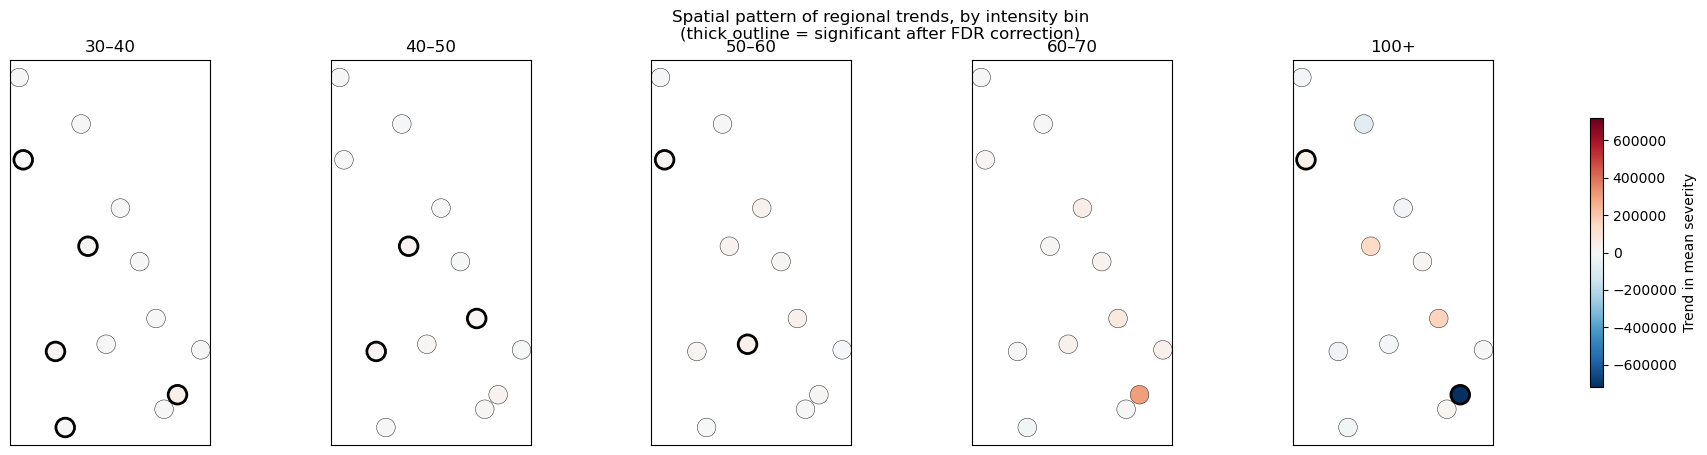

In [20]:
# Reconcile column naming between trend_df ('region') and the main dataframe ('geo_region')
region_centroids = (
    rainfall_events_all_df.groupby('geo_region')[['x_coord', 'y_coord']]
    .mean().reset_index().rename(columns={'geo_region': 'region'}))

trend_with_coords = trend_df.merge(region_centroids, on='region', how='left')

intensity_bins_available = trend_with_coords['intensity_bin'].cat.categories if hasattr(trend_with_coords['intensity_bin'], 'cat') else trend_with_coords['intensity_bin'].unique()

fig, axes = plt.subplots(1, len(intensity_bins_available), figsize=(5*len(intensity_bins_available), 5), sharex=True, sharey=True)

vmax = np.nanmax(np.abs(trend_with_coords['slope']))

for ax, ibin in zip(axes, intensity_bins_available):
    sub = trend_with_coords[trend_with_coords['intensity_bin'] == ibin]
    edgewidths = np.where(sub['p_value'] < 0.05, 2.0, 0.3)  # use p_adjusted if you've applied the FDR correction

    sc = ax.scatter(sub['x_coord'], sub['y_coord'], c=sub['slope'], cmap='RdBu_r',
                     vmin=-vmax, vmax=vmax, s=180, edgecolor='k', linewidth=edgewidths)
    ax.set_title(ibin)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(sc, ax=axes, label='Trend in mean severity', shrink=0.7)
fig.suptitle('Spatial pattern of regional trends, by intensity bin\n(thick outline = significant after FDR correction)')
plt.show()